In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

from sklearn.ensemble import IsolationForest

GRAINE = 42

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [2]:
fichiers = glob.glob("/content/*_alerts.txt")
print("Nombre de fichiers :", len(fichiers))
print(*fichiers, sep="\n")

Nombre de fichiers : 8
/content/fox_alerts.txt
/content/wardbeck_alerts.txt
/content/wilson_alerts.txt
/content/shaw_alerts.txt
/content/harrison_alerts.txt
/content/santos_alerts.txt
/content/wheeler_alerts.txt
/content/russellmitchell_alerts.txt


In [3]:
# 1. Chercher les fichiers déjà présents dans Colab
fichiers = sorted(glob.glob("/content/*_alerts.txt"))

# Si les 8 fichiers ne sont pas présents, proposer le téléversement
if len(fichiers) != 8:
    from google.colab import files

    print(f"{len(fichiers)} fichier(s) trouvé(s).")
    print("Sélectionne les fichiers manquants dans la fenêtre.")
    files.upload()

    fichiers = sorted(glob.glob("/content/*_alerts.txt"))

# Vérifier qu'on dispose bien de 8 fichiers avant de continuer
if len(fichiers) != 8:
    raise ValueError(
        f"Il faut 8 fichiers *_alerts.txt, mais {len(fichiers)} ont été trouvés."
    )

# 2 et 3. Lire chaque fichier et ajouter son réseau
tableaux = []

for fichier in fichiers:
    tableau = pd.read_csv(fichier)

    nom_fichier = fichier.split("/")[-1]
    reseau = nom_fichier.replace("_alerts.txt", "")
    tableau["reseau"] = reseau

    tableaux.append(tableau)

# 4. Regrouper les 8 tableaux et renuméroter les lignes
alertes = pd.concat(tableaux, ignore_index=True)

# Libérer les tableaux séparés, devenus inutiles
del tableaux

# 5. Mettre event_label de côté et supprimer time_label
enveloppe = alertes.pop("event_label")
alertes.drop(columns="time_label", inplace=True)

# 6. Identifier le détecteur à partir de la première lettre de short
alertes["source"] = alertes["short"].str[0].map({
    "W": "Wazuh",
    "S": "Suricata",
    "A": "AMiner"
})

# 7. Calculer l'heure de début de chaque réseau et l'heure relative
debut = alertes.groupby("reseau")["time"].transform("min")
alertes["heure"] = (alertes["time"] - debut) / 3600

# 8. Afficher les informations demandées
print("Nombre d'alertes :", len(alertes))
print("Nombre de réseaux :", alertes["reseau"].nunique())
print("Nombre de types :", alertes["short"].nunique())

display(alertes.head())

Nombre d'alertes : 2655821
Nombre de réseaux : 8
Nombre de types : 75


,time,name,ip,host,short,reseau,source,heure
0,1642213952,Wazuh: ClamAV database update,172.17.131.81,mail,W-Sys-Cav,fox,Wazuh,2.541944
1,1642213952,Wazuh: ClamAV database update,192.168.128.170,jonesmorgan_mail,W-Sys-Cav,fox,Wazuh,2.541944
2,1642213957,Wazuh: ClamAV database update,172.17.131.81,mail,W-Sys-Cav,fox,Wazuh,2.543333
3,1642213962,Wazuh: ClamAV database update,172.17.131.81,mail,W-Sys-Cav,fox,Wazuh,2.544722
4,1642213967,Wazuh: ClamAV database update,172.17.131.81,mail,W-Sys-Cav,fox,Wazuh,2.546111


In [11]:
# Partie 4.3 : construire les fenêtres de 10 minutes
TAILLE = 600

alertes["fenetre"] = ((alertes["time"] - debut) // TAILLE).astype(int)

matrice = pd.crosstab(
    [alertes["reseau"], alertes["host"], alertes["fenetre"]],
    alertes["short"]
)

infos_fenetres = matrice.index.to_frame(index=False)

masque_jour1 = (infos_fenetres["fenetre"] < 144).to_numpy()
masque_surveille = ~masque_jour1

Xl = np.log1p(matrice.to_numpy(dtype=float))
X_train = Xl[masque_jour1]

print("Matrice :", Xl.shape)
print("Entraînement :", X_train.shape)
print("Surveillance :", Xl[masque_surveille].shape)

# Partie 5 : entraîner le modèle et calculer les scores
iso = IsolationForest(
    n_estimators=300,
    max_samples=256,
    max_features=1.0,
    contamination="auto",
    bootstrap=False,
    random_state=GRAINE,
    n_jobs=-1
)

iso.fit(X_train)
s = -iso.score_samples(Xl)

print("Modèle entraîné et scores calculés.")

Matrice : (19722, 75)
Entraînement : (4385, 75)
Surveillance : (15337, 75)
Modèle entraîné et scores calculés.


In [12]:
top_8 = alertes["name"].value_counts().head(8)

bruit = pd.DataFrame({
    "Nombre d'alertes": top_8,
    "Pourcentage": (top_8 / len(alertes) * 100).round(1)
})

display(bruit)

,Nombre d'alertes,Pourcentage
name,,
Wazuh: Web server 400 error code.,1571313,59.2
Wazuh: IDS event.,295032,11.1
Wazuh: Dovecot Authentication Success.,276855,10.4
Wazuh: Multiple web server 400 error codes from same source ip.,121794,4.6
Suricata: Alert - SURICATA TLS invalid record/traffic,105043,4.0
Suricata: Alert - SURICATA TLS invalid handshake message,105016,4.0
Suricata: Alert - ET INFO Observed DNS Query to .biz TLD,91761,3.5
AMiner: New request method in Apache Access log.,27342,1.0


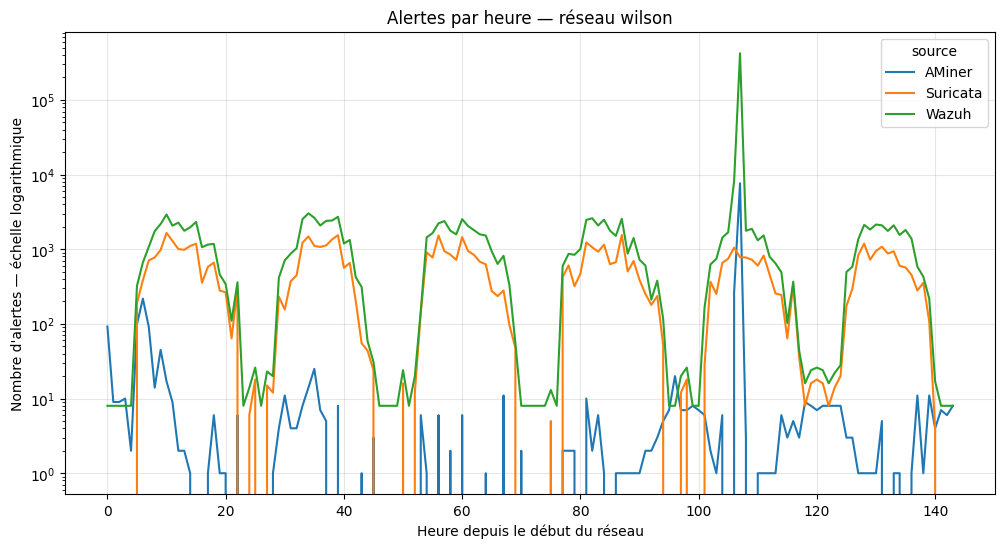

In [13]:
RESEAU = "wilson"

reseau_alertes = alertes[alertes["reseau"] == RESEAU].copy()
reseau_alertes["heure_entiere"] = reseau_alertes["heure"].astype(int)

chronologie = pd.crosstab(
    reseau_alertes["heure_entiere"],
    reseau_alertes["source"]
)

chronologie.plot(figsize=(12, 6), logy=True)
plt.xlabel("Heure depuis le début du réseau")
plt.ylabel("Nombre d'alertes — échelle logarithmique")
plt.title(f"Alertes par heure — réseau {RESEAU}")
plt.grid(alpha=0.3)
plt.show()

In [14]:
traduction = (
    alertes.groupby("short")["name"]
    .agg(lambda noms: noms.value_counts().index[0])
)

display(traduction.head())

,name
short,
A-Acc-Chr1,AMiner: New characters in Apache Access referer.
A-Acc-Chr2,AMiner: New characters in Apache Access request.
A-Acc-Clc,AMiner: Unusual occurrence frequencies of Apache Access request methods.
A-Acc-Ent1,AMiner: High entropy in Apache Access referer.
A-Acc-Ent2,AMiner: High entropy in Apache Access request.


In [15]:
premier_arbre = iso.estimators_[0].tree_

print("Nombre d'arbres :", len(iso.estimators_))
print("Fenêtres par arbre :", iso.max_samples_)
print("Profondeur du premier arbre :", premier_arbre.max_depth)
print("Nombre de leaves :", premier_arbre.n_leaves)

Nombre d'arbres : 300
Fenêtres par arbre : 256
Profondeur du premier arbre : 8
Nombre de leaves : 20


In [16]:
s = -iso.score_samples(Xl)
d = iso.decision_function(Xl)
p = iso.predict(Xl)

print("Offset :", iso.offset_)

resultats = pd.DataFrame({
    "score s": s[:3],
    "decision_function": d[:3],
    "predict": p[:3]
}).round(3)

display(resultats)

Offset : -0.5


,score s,decision_function,predict
0,0.490,0.010,1
1,0.352,0.148,1
2,0.334,0.166,1


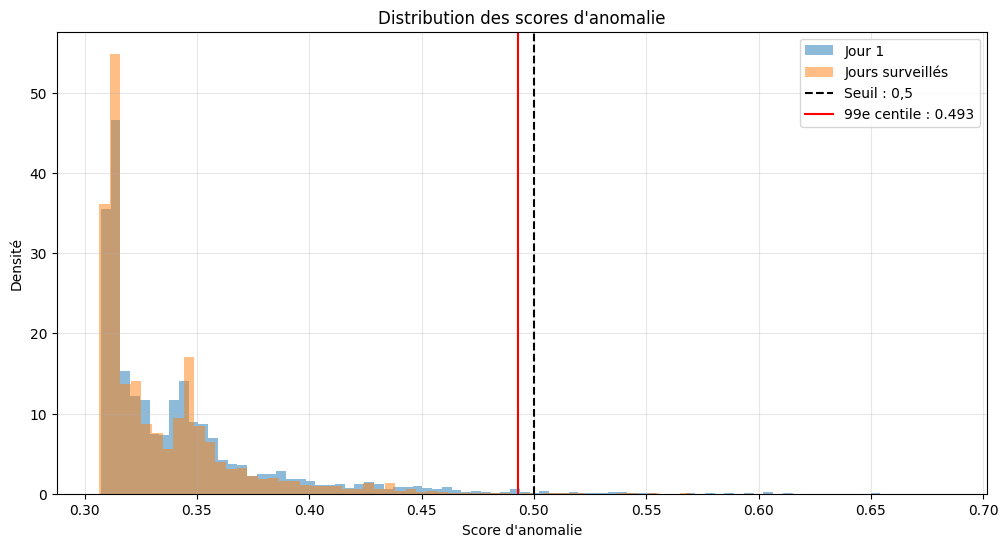

Médiane : 0.326
90e centile : 0.390
99e centile : 0.493
Maximum : 0.654


In [17]:
scores_jour1 = s[masque_jour1]
scores_surveille = s[masque_surveille]

seuil_99 = np.percentile(scores_jour1, 99)

plt.figure(figsize=(12, 6))

plt.hist(scores_jour1, bins=80, density=True, alpha=0.5, label="Jour 1")
plt.hist(scores_surveille, bins=80, density=True, alpha=0.5, label="Jours surveillés")

plt.axvline(0.5, color="black", linestyle="--", label="Seuil : 0,5")
plt.axvline(seuil_99, color="red", label=f"99e centile : {seuil_99:.3f}")

plt.xlabel("Score d'anomalie")
plt.ylabel("Densité")
plt.title("Distribution des scores d'anomalie")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Médiane : {np.median(scores_jour1):.3f}")
print(f"90e centile : {np.percentile(scores_jour1, 90):.3f}")
print(f"99e centile : {seuil_99:.3f}")
print(f"Maximum : {np.max(scores_jour1):.3f}")

In [18]:
seuil_auto = 0.5
seuil_q99 = np.percentile(s[masque_jour1], 99)

alerte_auto = masque_surveille & (s > seuil_auto)
alerte = masque_surveille & (s > seuil_q99)

dernieres_fenetres = alertes.groupby("reseau")["fenetre"].max()
jours_surveilles = ((dernieres_fenetres + 1 - 144) * TAILLE / 86400).sum()

print(f"Seuil automatique : {seuil_auto}")
print(f"Fenêtres signalées : {alerte_auto.sum()}")
print(f"Moyenne par réseau et par jour : {alerte_auto.sum() / jours_surveilles:.2f}")

print(f"\nSeuil 99e centile : {seuil_q99:.3f}")
print(f"Fenêtres signalées : {alerte.sum()}")
print(f"Moyenne par réseau et par jour : {alerte.sum() / jours_surveilles:.2f}")

Seuil automatique : 0.5
Fenêtres signalées : 37
Moyenne par réseau et par jour : 1.16

Seuil 99e centile : 0.493
Fenêtres signalées : 41
Moyenne par réseau et par jour : 1.28


In [19]:
# Indices des 10 scores surveillés les plus élevés
indices_surveillance = np.flatnonzero(masque_surveille)
top_indices = indices_surveillance[np.argsort(s[indices_surveillance])[-10:][::-1]]

# Construire le tableau à partir des fenêtres et des comptages
top_fenetres = infos_fenetres.iloc[top_indices].copy()

top_fenetres["heure"] = (
    top_fenetres["fenetre"] * TAILLE / 3600
).round(1)

top_fenetres["score"] = np.round(s[top_indices], 3)
top_fenetres["alertes"] = matrice.iloc[top_indices].sum(axis=1).to_numpy()

top_fenetres = top_fenetres[
    ["reseau", "host", "heure", "score", "alertes"]
].reset_index(drop=True)

display(top_fenetres)

,reseau,host,heure,score,alertes
0,santos,mail,56.3,0.683,173
1,wardbeck,intranet_server,108.2,0.646,6046
2,santos,intranet_server,83.3,0.626,11101
3,wheeler,intranet_server,103.8,0.575,168167
4,wardbeck,intranet_server,56.7,0.574,27
5,wardbeck,intranet_server,58.3,0.568,30
6,wilson,intranet_server,107.3,0.568,6370
7,fox,intranet_server,84.5,0.553,166871
8,harrison,intranet_server,104.5,0.553,59
9,shaw,intranet_server,111.3,0.552,46


In [20]:
def expliquer(i, top=5):
    poids = np.zeros(Xl.shape[1])

    for arbre, variables in zip(iso.estimators_, iso.estimators_features_):
        chemin = arbre.decision_path(Xl[i:i+1, variables]).indices
        arbre_info = arbre.tree_

        for parent, enfant in zip(chemin[:-1], chemin[1:]):
            position = arbre_info.feature[parent]
            colonne = variables[position]

            n_parent = arbre_info.n_node_samples[parent]
            n_enfant = arbre_info.n_node_samples[enfant]

            poids[colonne] += 1 - n_enfant / n_parent

    if poids.sum() == 0:
        print("Aucune coupure à expliquer pour cette fenêtre.")
        return pd.DataFrame(columns=["part", "alertes", "libellé"])

    poids = poids / poids.sum()
    indices_top = np.argsort(poids)[-top:][::-1]
    codes = matrice.columns[indices_top]

    return pd.DataFrame({
        "part": np.round(poids[indices_top], 2),
        "alertes": matrice.iloc[i, indices_top].to_numpy(),
        "libellé": traduction.reindex(codes).to_numpy()
    }, index=codes)


# Fenêtre surveillée avec le plus grand score dans RESEAU
indices_reseau = np.flatnonzero(
    masque_surveille & (infos_fenetres["reseau"].to_numpy() == RESEAU)
)

i_max = indices_reseau[np.argmax(s[indices_reseau])]
fenetre_max = infos_fenetres.iloc[i_max]

print("Réseau :", RESEAU)
print("Hôte :", fenetre_max["host"])
print(f"Heure : {fenetre_max['fenetre'] * TAILLE / 3600:.1f}")
print(f"Score : {s[i_max]:.3f}")

display(expliquer(i_max))

Réseau : wilson
Hôte : intranet_server
Heure : 107.3
Score : 0.568


,part,alertes,libellé
short,,,
W-Acc-Cms,0.13,9,Wazuh: CMS (WordPress or Joomla) login attempt.
A-Acc-Chr2,0.12,2,AMiner: New characters in Apache Access request.
A-Acc-Val2,0.12,6,AMiner: New status code in Apache Access log.
A-Acc-Val1,0.11,3169,AMiner: New request method in Apache Access log.
A-All-Evt,0.10,14,AMiner: New event type.


In [21]:
resultats_psi = []

for psi in [64, 256, 1024, len(X_train)]:
    modele = IsolationForest(
        n_estimators=300,
        max_samples=psi,
        max_features=1.0,
        contamination="auto",
        bootstrap=False,
        random_state=GRAINE,
        n_jobs=-1
    )

    modele.fit(X_train)

    scores = -modele.score_samples(Xl)
    seuil = np.percentile(scores[masque_jour1], 99)
    alertes_psi = masque_surveille & (scores > seuil)

    resultats_psi.append({
        "ψ": psi,
        "Fenêtres signalées": int(alertes_psi.sum()),
        "En commun avec ψ = 256": int((alertes_psi & alerte).sum())
    })

display(pd.DataFrame(resultats_psi))

,ψ,Fenêtres signalées,En commun avec ψ = 256
0,64,65,7
1,256,41,41
2,1024,45,38
3,4385,49,38


In [22]:
from scipy.stats import spearmanr

resultats_arbres = []

for nombre in [10, 50, 100, 300]:
    scores_graines = []

    for graine in [1, 2]:
        modele = IsolationForest(
            n_estimators=nombre,
            random_state=graine,
            n_jobs=-1
        )

        modele.fit(X_train)
        scores_graines.append(-modele.score_samples(Xl))

    correlation = spearmanr(scores_graines[0], scores_graines[1]).statistic

    resultats_arbres.append({
        "Nombre d'arbres": nombre,
        "Corrélation de rang": round(correlation, 3)
    })

display(pd.DataFrame(resultats_arbres))

,Nombre d'arbres,Corrélation de rang
0,10,0.686
1,50,0.961
2,100,0.973
3,300,0.982


In [23]:
# Fenêtres signalées, en conservant leurs indices d'origine
F = infos_fenetres.loc[alerte].copy()
F["s"] = s[alerte]

F = F.sort_values(["reseau", "fenetre", "host"])

# Nouvel incident si changement de réseau ou écart supérieur à 6 fenêtres
nouvel_incident = (
    F["reseau"].ne(F["reseau"].shift())
    | (F.groupby("reseau")["fenetre"].diff() > 6)
)

F["incident"] = nouvel_incident.cumsum()

incidents = F.groupby("incident").agg(
    reseau=("reseau", "first"),
    premiere=("fenetre", "min"),
    derniere=("fenetre", "max"),
    fenetres=("fenetre", "size"),
    hotes=("host", "nunique"),
    score_total=("s", "sum")
)

incidents["debut_h"] = (incidents["premiere"] * TAILLE / 3600).round(1)
incidents["duree_min"] = (
    (incidents["derniere"] - incidents["premiere"] + 1) * TAILLE / 60
)

incidents = incidents.sort_values(
    ["reseau", "hotes", "score_total"],
    ascending=[True, False, False]
)

incidents["rang"] = incidents.groupby("reseau").cumcount() + 1

incidents = incidents[
    ["reseau", "debut_h", "duree_min", "fenetres", "hotes", "score_total", "rang"]
]

print("Nombre total d'incidents :", len(incidents))
display(incidents[incidents["reseau"] == RESEAU].sort_values("rang"))

Nombre total d'incidents : 21


,reseau,debut_h,duree_min,fenetres,hotes,score_total,rang
incident,,,,,,,
21,wilson,106.8,40.0,3,1,1.570198,1
19,wilson,33.7,70.0,2,1,1.017053,2
20,wilson,67.7,10.0,1,1,0.508632,3


In [24]:
incident_1 = incidents[
    (incidents["reseau"] == RESEAU) & (incidents["rang"] == 1)
].index[0]

dossier = []

for i, ligne in F[F["incident"] == incident_1].iterrows():
    explication = expliquer(i, top=3)

    types_alertes = [
        str(libelle).split(": ", 1)[-1]
        for libelle in explication["libellé"]
    ]

    dossier.append({
        "heure": round(ligne["fenetre"] * TAILLE / 3600, 1),
        "hôte": ligne["host"],
        "score": round(ligne["s"], 3),
        "top 3 alertes": " | ".join(types_alertes)
    })

display(pd.DataFrame(dossier))

,heure,hôte,score,top 3 alertes
0,106.8,intranet_server,0.496,New characters in Apache Access request. | New event type. | New status code...
1,107.2,intranet_server,0.507,New characters in Apache Access request. | New status code in Apache Access ...
2,107.3,intranet_server,0.568,CMS (WordPress or Joomla) login attempt. | New characters in Apache Access r...


In [25]:
alertes["etape"] = enveloppe

ETAPES = [
    "service_scan",
    "wpscan",
    "dirb",
    "webshell_cmd",
    "online_cracking",
    "crack_passwords",
    "attacker_change_user",
    "escalated_sudo_command",
    "dns_scan"
]

# Regrouper uniquement les étapes recherchées par fenêtre
etapes_groupees = (
    alertes[alertes["etape"].isin(ETAPES)]
    .groupby(["reseau", "host", "fenetre"])["etape"]
    .agg(set)
)

# Aligner sur les lignes de la matrice
etapes_fenetre = etapes_groupees.reindex(matrice.index)
etapes_fenetre = etapes_fenetre.apply(
    lambda x: x if isinstance(x, set) else set()
)

intrusion = etapes_fenetre.map(bool).to_numpy()

nb_signalees = int(alerte.sum())
nb_retrouvees = int((alerte & intrusion).sum())
nb_intrusions_surveillees = int((masque_surveille & intrusion).sum())

print("Fenêtres signalées :", nb_signalees)
print("Fenêtres signalées contenant l'attaquant :", nb_retrouvees)
print(f"Précision : {nb_retrouvees / nb_signalees:.1%}" if nb_signalees else "Précision : non définie")
print(f"Intrusions surveillées retrouvées : {nb_retrouvees / nb_intrusions_surveillees:.1%}"
      if nb_intrusions_surveillees else "Rappel : non défini")

# Tableau étapes × réseaux
tableau_etapes = pd.DataFrame(
    "",
    index=ETAPES,
    columns=sorted(infos_fenetres["reseau"].unique())
)

for etape in ETAPES:
    contient_etape = etapes_fenetre.map(lambda ensemble: etape in ensemble).to_numpy()

    for reseau in tableau_etapes.columns:
        dans_reseau = infos_fenetres["reseau"].to_numpy() == reseau
        presente = contient_etape & dans_reseau

        if presente.any():
            tableau_etapes.loc[etape, reseau] = (
                "OUI" if (presente & alerte).any() else "non"
            )

display(tableau_etapes)

Fenêtres signalées : 41
Fenêtres signalées contenant l'attaquant : 23
Précision : 56.1%
Intrusions surveillées retrouvées : 32.4%


,fox,harrison,russellmitchell,santos,shaw,wardbeck,wheeler,wilson
service_scan,OUI,non,OUI,OUI,,OUI,OUI,OUI
wpscan,OUI,OUI,OUI,OUI,OUI,OUI,OUI,OUI
dirb,OUI,OUI,OUI,OUI,OUI,OUI,OUI,OUI
webshell_cmd,OUI,OUI,OUI,OUI,OUI,OUI,OUI,OUI
online_cracking,OUI,,,OUI,,,,
crack_passwords,non,non,non,non,non,non,,non
attacker_change_user,OUI,OUI,OUI,OUI,OUI,non,OUI,non
escalated_sudo_command,OUI,OUI,OUI,OUI,OUI,non,OUI,non
dns_scan,,,,,non,,,


In [26]:
F["attaque"] = intrusion[F.index.to_numpy()]

attaque_par_incident = F.groupby("incident")["attaque"].any()

incidents_verifies = incidents.copy()
incidents_verifies["attaque"] = attaque_par_incident.reindex(
    incidents_verifies.index
)

bilan_incidents = incidents_verifies.groupby("reseau").agg(
    nombre_incidents=("rang", "size")
)

meilleurs_rangs = (
    incidents_verifies[incidents_verifies["attaque"]]
    .groupby("reseau")["rang"]
    .min()
)

bilan_incidents["meilleur_rang_attaque"] = meilleurs_rangs

display(bilan_incidents)

,nombre_incidents,meilleur_rang_attaque
reseau,,
fox,1,1
harrison,1,1
russellmitchell,1,1
santos,2,1
shaw,5,1
wardbeck,4,3
wheeler,4,1
wilson,3,1


In [27]:
comparaison_psi = []

for psi in [64, 256, 1024, len(X_train)]:
    modele = IsolationForest(
        n_estimators=300,
        max_samples=psi,
        max_features=1.0,
        contamination="auto",
        bootstrap=False,
        random_state=GRAINE,
        n_jobs=-1
    )

    modele.fit(X_train)

    scores = -modele.score_samples(Xl)
    seuil = np.percentile(scores[masque_jour1], 99)
    signalees = masque_surveille & (scores > seuil)

    nombre = int(signalees.sum())
    trouvees = int((signalees & intrusion).sum())

    comparaison_psi.append({
        "ψ": psi,
        "Fenêtres signalées": nombre,
        "Précision": round(trouvees / nombre, 3) if nombre else np.nan,
        "Intrusions retrouvées": (
            round(trouvees / nb_intrusions_surveillees, 3)
            if nb_intrusions_surveillees else np.nan
        )
    })

display(pd.DataFrame(comparaison_psi))

,ψ,Fenêtres signalées,Précision,Intrusions retrouvées
0,64,65,0.046,0.042
1,256,41,0.561,0.324
2,1024,45,0.556,0.352
3,4385,49,0.571,0.394


In [28]:
attaque_reseau = alertes[
    (alertes["reseau"] == RESEAU) & alertes["etape"].isin(ETAPES)
].copy()

print(f"Début de l'attaque : h+{attaque_reseau['heure'].min():.1f}")
print(f"Fin de l'attaque : h+{attaque_reseau['heure'].max():.1f}")
print("Hôtes touchés :", sorted(attaque_reseau["host"].dropna().unique()))

rapport_etapes = (
    attaque_reseau.groupby("etape")
    .agg(
        premiere_heure=("heure", "min"),
        derniere_heure=("heure", "max"),
        nombre_alertes=("etape", "size")
    )
    .sort_values("premiere_heure")
)

rapport_etapes[["premiere_heure", "derniere_heure"]] = (
    rapport_etapes[["premiere_heure", "derniere_heure"]].round(1)
)

display(rapport_etapes)

Début de l'attaque : h+107.0
Fin de l'attaque : h+107.8
Hôtes touchés : ['cloud_share', 'inet-firewall', 'intranet_server', 'mail', 'monitoring', 'vpn', 'webserver']


,premiere_heure,derniere_heure,nombre_alertes
etape,,,
service_scan,107.0,107.0,50
dirb,107.0,107.3,428239
wpscan,107.3,107.3,6401
webshell_cmd,107.3,107.4,3
crack_passwords,107.5,107.5,1
attacker_change_user,107.8,107.8,11
escalated_sudo_command,107.8,107.8,8


In [29]:
alertes_biz = alertes[
    alertes["name"].str.contains(".biz TLD", regex=False, na=False)
].copy()

alertes_biz["jour"] = (alertes_biz["heure"] // 24).astype(int)

comparaison_dns = pd.crosstab(
    [alertes_biz["reseau"], alertes_biz["host"]],
    alertes_biz["jour"]
)

display(comparaison_dns)

jour                                0     1     2     3     4
reseau          host                                         
fox             inet-firewall       0     0     0     6     0
harrison        inet-firewall    5410  5377  5350  5386  2068
                internal_share   5411  5377  5350  5386  2068
russellmitchell inet-firewall       0     0     9     0     0
santos          inet-firewall    5579  5579  1705     0     0
                internal_share   5580  5573  1701     0     0
wardbeck        inet-firewall       0     6     0     0     0
wheeler         inet-firewall     374   451   369   433   458
                intranet_server    34    24    27    28    24
                vpn              3257  2606  3383  3505  3043
                webserver         217   141   144   159   161
wilson          inet-firewall       1     0     0     0     0
                vpn                 1     0     0     0     0

In [30]:
dnsteal = (
    alertes[alertes["etape"] == "dnsteal"]
    .groupby(["reseau", "host"])
    .size()
    .rename("nombre_alertes")
    .reset_index()
)

display(dnsteal)

,reseau,host,nombre_alertes
0,fox,inet-firewall,4
1,fox,internal_share,2
2,harrison,inet-firewall,23596
3,harrison,internal_share,23594
4,russellmitchell,inet-firewall,4
5,russellmitchell,internal_share,2
6,santos,inet-firewall,12855
7,santos,internal_share,12856
8,shaw,internal_share,2
9,wardbeck,inet-firewall,2
